# Lightweight Models

Compare efficient model architectures.

In [1]:

import os
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("All imports completed successfully!")
print("PyTorch version:", torch.__version__)
print("Torchvision models ready!")
print("CUDA available:", torch.cuda.is_available())


All imports completed successfully!
PyTorch version: 2.14.1+cpu
Torchvision models ready!
CUDA available: False


In [2]:

# Load the existing dataset splits
train_df = pd.read_csv("../data/metadata/train_split.csv")
val_df = pd.read_csv("../data/metadata/val_split.csv")
test_df = pd.read_csv("../data/metadata/test_split.csv")

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("\nTraining data preview:")
display(train_df.head())

print("\nColumns available:")
print(train_df.columns.tolist())


Training samples: 1740
Validation samples: 435
Testing samples: 977

Training data preview:


,Image Name,Majority Vote Label,Number of Annotators who Selected SSA (Out of 7),Partition
0,MHIST_edl.png,SSA,5,train
1,MHIST_cda.png,HP,0,train
2,MHIST_cls.png,HP,0,train
3,MHIST_aal.png,SSA,5,train
4,MHIST_djr.png,SSA,7,train



Columns available:
['Image Name', 'Majority Vote Label', 'Number of Annotators who Selected SSA (Out of 7)', 'Partition']


In [3]:

# Path to the actual image folder
image_dir = os.path.abspath("../data/raw/images/images")

# Check that the folder exists
print("Image folder exists:", os.path.isdir(image_dir))
print("Image folder:", image_dir)

# Define the class-to-number mapping
label_map = {
    "HP": 0,
    "SSA": 1
}

print("\nLabel mapping:", label_map)

# Check the labels in each split
print("\nTraining labels:")
print(train_df["Majority Vote Label"].value_counts())

print("\nValidation labels:")
print(val_df["Majority Vote Label"].value_counts())

print("\nTest labels:")
print(test_df["Majority Vote Label"].value_counts())


Image folder exists: True
Image folder: c:\Users\hp\OneDrive\Desktop\MHIST-Research\Deep-learning-PBL-3\MHIST-Research\data\raw\images\images

Label mapping: {'HP': 0, 'SSA': 1}

Training labels:
Majority Vote Label
HP     1236
SSA     504
Name: count, dtype: int64

Validation labels:
Majority Vote Label
HP     309
SSA    126
Name: count, dtype: int64

Test labels:
Majority Vote Label
HP     617
SSA    360
Name: count, dtype: int64


In [4]:

from torchvision import transforms

# Transformations for training images
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Transformations for validation and test images
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Training transformations ready!")
print("Validation and test transformations ready!")


Training transformations ready!
Validation and test transformations ready!


In [5]:

from torch.utils.data import Dataset, DataLoader
from PIL import Image

class MHISTDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_name = row["Image Name"]
        label_name = row["Majority Vote Label"]

        image_path = os.path.join(self.image_dir, image_name)

        image = Image.open(image_path).convert("RGB")
        label = label_map[label_name]

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

print("MHISTDataset class created successfully!")


MHISTDataset class created successfully!


In [6]:

# Create datasets
train_dataset = MHISTDataset(
    train_df, image_dir, transform=train_transform
)

val_dataset = MHISTDataset(
    val_df, image_dir, transform=eval_transform
)

test_dataset = MHISTDataset(
    test_df, image_dir, transform=eval_transform
)

# Create DataLoaders
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

print("Datasets and DataLoaders created successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Datasets and DataLoaders created successfully!
Training batches: 55
Validation batches: 14
Test batches: 31


Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Image data type: torch.float32
Label data type: torch.int64
Labels in this batch: [0, 1]


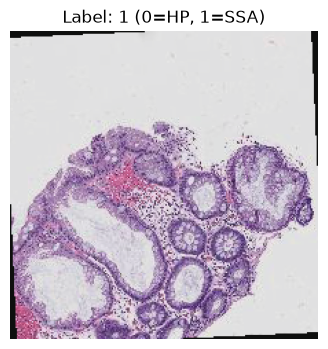

In [7]:

# Get one batch of training data
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)
print("Labels in this batch:", torch.unique(labels).tolist())

# Display one image
image = images[0].permute(1, 2, 0).numpy()

# Undo normalization for display
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
image = np.clip(image * std + mean, 0, 1)

plt.figure(figsize=(4, 4))
plt.imshow(image)
plt.title(f"Label: {labels[0].item()} (0=HP, 1=SSA)")
plt.axis("off")
plt.show()


In [8]:

# Load pretrained MobileNetV3-Small
weights = models.MobileNet_V3_Small_Weights.DEFAULT

mobilenet = models.mobilenet_v3_small(weights=weights)

# Replace the final classifier layer for 2 classes
num_features = mobilenet.classifier[3].in_features
mobilenet.classifier[3] = nn.Linear(num_features, 2)

# Select the available device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

mobilenet = mobilenet.to(device)

print("MobileNetV3-Small loaded successfully!")
print("Number of output classes:", mobilenet.classifier[3].out_features)
print("Using device:", device)


Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to C:\Users\hp/.cache\torch\hub\checkpoints\mobilenet_v3_small-047dcff4.pth


100.0%


MobileNetV3-Small loaded successfully!
Number of output classes: 2
Using device: cpu


In [9]:

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = torch.optim.Adam(
    mobilenet.parameters(),
    lr=0.0001
)

print("Loss function:", criterion)
print("Optimizer: Adam")
print("Learning rate: 0.0001")
print("Model is ready for training!")


Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.0001
Model is ready for training!


In [10]:

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


def evaluate_one_epoch(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


print("Training and validation functions created successfully!")


Training and validation functions created successfully!


In [11]:

# Training history
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

best_val_accuracy = 0.0
best_model_state = None

num_epochs = 5

start_time = time.time()

for epoch in range(num_epochs):

    train_loss, train_acc = train_one_epoch(
        mobilenet, train_loader, criterion, optimizer, device
    )

    val_loss, val_acc = evaluate_one_epoch(
        mobilenet, val_loader, criterion, device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    if val_acc > best_val_accuracy:
        best_val_accuracy = val_acc
        best_model_state = copy.deepcopy(mobilenet.state_dict())

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

# Restore the weights from the best validation epoch
mobilenet.load_state_dict(best_model_state)

elapsed_time = (time.time() - start_time) / 60

print("\nTraining completed!")
print(f"Best validation accuracy: {best_val_accuracy:.4f}")
print(f"Training time: {elapsed_time:.2f} minutes")


Epoch [1/5] Train Loss: 0.5443 | Train Acc: 0.7207 | Val Loss: 0.6086 | Val Acc: 0.7172
Epoch [2/5] Train Loss: 0.3992 | Train Acc: 0.8126 | Val Loss: 0.5979 | Val Acc: 0.7425
Epoch [3/5] Train Loss: 0.3504 | Train Acc: 0.8356 | Val Loss: 0.5634 | Val Acc: 0.7586
Epoch [4/5] Train Loss: 0.2970 | Train Acc: 0.8713 | Val Loss: 0.3897 | Val Acc: 0.8230
Epoch [5/5] Train Loss: 0.2831 | Train Acc: 0.8753 | Val Loss: 0.2959 | Val Acc: 0.8736

Training completed!
Best validation accuracy: 0.8736
Training time: 8.11 minutes


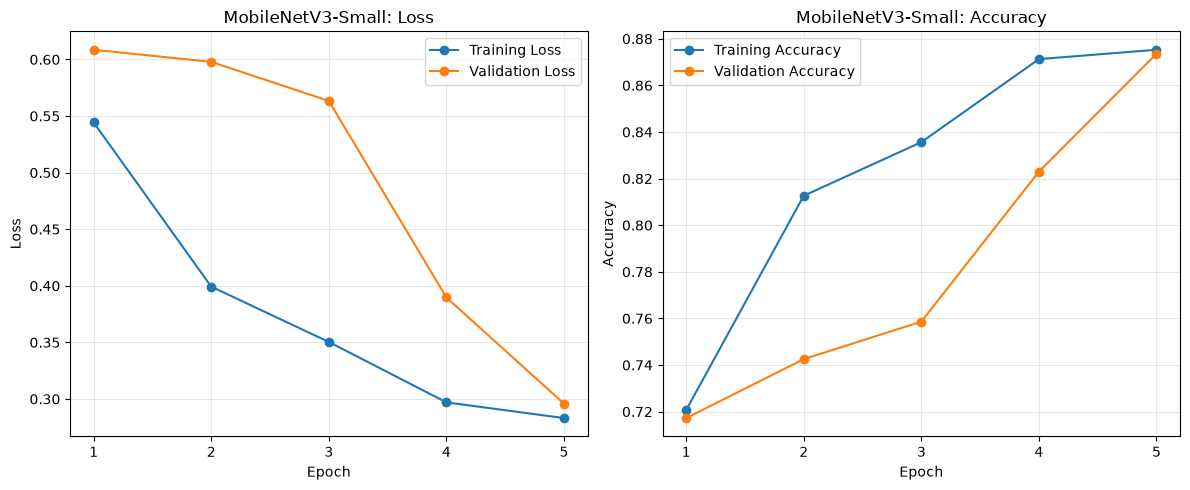

In [12]:

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(12, 5))

# Loss curves
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, marker="o", label="Training Loss")
plt.plot(epochs, val_losses, marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNetV3-Small: Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True, alpha=0.3)

# Accuracy curves
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, marker="o", label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV3-Small: Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [13]:

mobilenet.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = mobilenet(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

# Calculate test metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(
    all_labels, all_predictions, zero_division=0
)
recall = recall_score(
    all_labels, all_predictions, zero_division=0
)
f1 = f1_score(
    all_labels, all_predictions, zero_division=0
)
roc_auc = roc_auc_score(
    all_labels, np.array(all_probabilities)[:, 1]
)

mobilenet_results = {
    "Model": "MobileNetV3-Small",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1,
    "ROC-AUC": roc_auc
}

print("MobileNetV3-Small — Test Results")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1],
    target_names=["HP", "SSA"],
    zero_division=0
))


MobileNetV3-Small — Test Results
Accuracy:  0.8352
Precision: 0.8902
Recall:    0.6306
F1 Score:  0.7382
ROC-AUC:   0.9224

Classification Report:
              precision    recall  f1-score   support

          HP       0.82      0.95      0.88       617
         SSA       0.89      0.63      0.74       360

    accuracy                           0.84       977
   macro avg       0.85      0.79      0.81       977
weighted avg       0.84      0.84      0.83       977



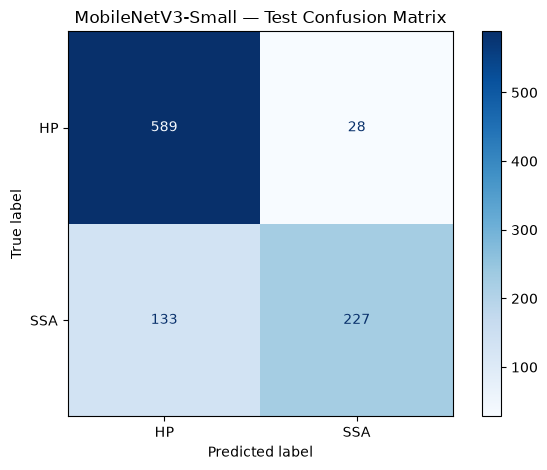

Confusion Matrix:
[[589  28]
 [133 227]]


In [14]:

# Create the confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["HP", "SSA"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("MobileNetV3-Small — Test Confusion Matrix")
plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm)


In [15]:

# Results from the two baseline models
resnet18_results = {
    "Model": "ResNet18",
    "Accuracy": 0.7922,
    "Precision": 0.6612,
    "Recall": 0.8944,
    "F1 Score": 0.7603,
    "ROC-AUC": 0.8949
}

efficientnet_results = {
    "Model": "EfficientNet-B0",
    "Accuracy": 0.8506,
    "Precision": 0.7716,
    "Recall": 0.8444,
    "F1 Score": 0.8064,
    "ROC-AUC": 0.9230
}

# Combine the results
comparison_df = pd.DataFrame([
    resnet18_results,
    efficientnet_results,
    mobilenet_results
])

# Display percentages
comparison_display = comparison_df.copy()

metric_columns = [
    "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"
]

comparison_display[metric_columns] = (
    comparison_display[metric_columns] * 100
).round(2)

print("Final Test-Set Model Comparison")
display(comparison_display)


Final Test-Set Model Comparison


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,ResNet18,79.22,66.12,89.44,76.03,89.49
1,EfficientNet-B0,85.06,77.16,84.44,80.64,92.30
2,MobileNetV3-Small,83.52,89.02,63.06,73.82,92.24


In [16]:

def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )
    return total, trainable


def get_model_size_mb(model):
    # Approximate size of the model weights in memory
    size_bytes = sum(
        p.numel() * p.element_size()
        for p in model.parameters()
    )
    return size_bytes / (1024 ** 2)


# Load the baseline architectures for comparison
resnet_model = models.resnet18(weights=None)
resnet_model.fc = nn.Linear(resnet_model.fc.in_features, 2)

efficientnet_model = models.efficientnet_b0(weights=None)
efficientnet_model.classifier[1] = nn.Linear(
    efficientnet_model.classifier[1].in_features, 2
)

models_to_compare = {
    "ResNet18": resnet_model,
    "EfficientNet-B0": efficientnet_model,
    "MobileNetV3-Small": mobilenet
}

efficiency_rows = []

for name, model in models_to_compare.items():
    total_params, trainable_params = count_parameters(model)

    efficiency_rows.append({
        "Model": name,
        "Total Parameters (M)": round(total_params / 1e6, 3),
        "Trainable Parameters (M)": round(trainable_params / 1e6, 3),
        "Weight Size (MB)": round(get_model_size_mb(model), 2)
    })

efficiency_df = pd.DataFrame(efficiency_rows)

print("Model Efficiency Comparison")
display(efficiency_df)


Model Efficiency Comparison


,Model,Total Parameters (M),Trainable Parameters (M),Weight Size (MB)
0,ResNet18,11.178,11.178,42.64
1,EfficientNet-B0,4.010,4.010,15.30
2,MobileNetV3-Small,1.520,1.520,5.80


In [17]:

import time

def measure_inference_time(model, device, input_shape=(1, 3, 224, 224), runs=50):
    model = model.to(device)
    model.eval()

    dummy_input = torch.randn(*input_shape).to(device)

    # Warm-up
    with torch.no_grad():
        for _ in range(5):
            _ = model(dummy_input)

    # Measure inference time
    start = time.perf_counter()

    with torch.no_grad():
        for _ in range(runs):
            _ = model(dummy_input)

    elapsed = time.perf_counter() - start

    return (elapsed / runs) * 1000  # milliseconds per image


# Measure all three models
inference_rows = []

for name, model in models_to_compare.items():
    model = model.to(device)
    latency_ms = measure_inference_time(model, device)

    inference_rows.append({
        "Model": name,
        "Inference Time (ms/image)": round(latency_ms, 2)
    })

inference_df = pd.DataFrame(inference_rows)

print("Inference Speed Comparison (single image)")
display(inference_df)


Inference Speed Comparison (single image)


,Model,Inference Time (ms/image)
0,ResNet18,43.91
1,EfficientNet-B0,44.33
2,MobileNetV3-Small,19.37


In [18]:

# Create results folder if it doesn't exist
os.makedirs("../results", exist_ok=True)

# Save test metrics
comparison_df.to_csv(
    "../results/model_comparison.csv",
    index=False
)

# Save parameter counts and model sizes
efficiency_df.to_csv(
    "../results/model_efficiency.csv",
    index=False
)

# Save inference timings
inference_df.to_csv(
    "../results/inference_speed.csv",
    index=False
)

print("Saved files:")
print("../results/model_comparison.csv")
print("../results/model_efficiency.csv")
print("../results/inference_speed.csv")


Saved files:
../results/model_comparison.csv
../results/model_efficiency.csv
../results/inference_speed.csv
